# Hostel Electricity Monitoring

Explore simulated hourly hostel electricity readings, detect unusual values, store results in SQL, and demonstrate a local socket connection.

## 1. Setup

In [12]:
%pip install -q pandas numpy matplotlib networkx mysql-connector-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\anike\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import sqlite3, socket, threading, json, time
from pathlib import Path
import networkx as nx
np.random.seed(42)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
print("Setup complete")

Setup complete


## 2. Generate sample data

In [14]:
times = pd.date_range("2026-09-01", periods=30*24, freq="h")
areas = ["Block A", "Block B", "Mess", "Common Room"]
rows = []
for area in areas:
    base = {"Block A":18, "Block B":21, "Mess":35, "Common Room":12}[area]
    pattern = 4*np.sin(2*np.pi*times.hour.to_numpy()/24)
    usage = np.maximum(1, base + pattern + np.random.normal(0, 2, len(times)))
    labels = np.zeros(len(times), dtype=int)
    spikes = np.random.choice(np.arange(24, len(times)-24), size=5, replace=False)
    usage[spikes] += np.random.uniform(18, 30, len(spikes))
    labels[spikes] = 1
    for i, ts in enumerate(times):
        rows.append({"timestamp":ts, "area":area, "kwh":round(float(usage[i]),2), "known_anomaly":int(labels[i])})
df = pd.DataFrame(rows).sort_values(["area","timestamp"]).reset_index(drop=True)
df.to_csv(DATA_DIR/"hostel_readings.csv", index=False)
print("Rows:", len(df))
display(df.head())

Rows: 2880


,timestamp,area,kwh,known_anomaly
0,2026-09-01 00:00:00,Block A,18.99,0
1,2026-09-01 01:00:00,Block A,18.76,0
2,2026-09-01 02:00:00,Block A,21.30,0
3,2026-09-01 03:00:00,Block A,23.87,0
4,2026-09-01 04:00:00,Block A,21.00,0


## 3. Explore usage

,mean,min,max
area,,,
Block A,18.15,9.23,47.34
Block B,21.17,11.47,53.10
Common Room,12.21,3.33,37.42
Mess,35.18,26.86,65.32


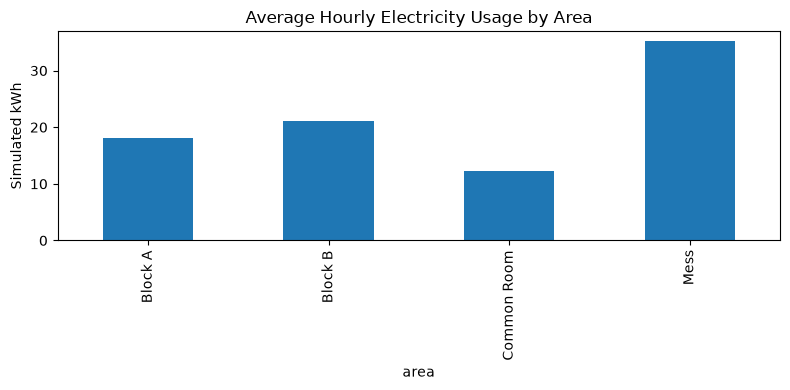

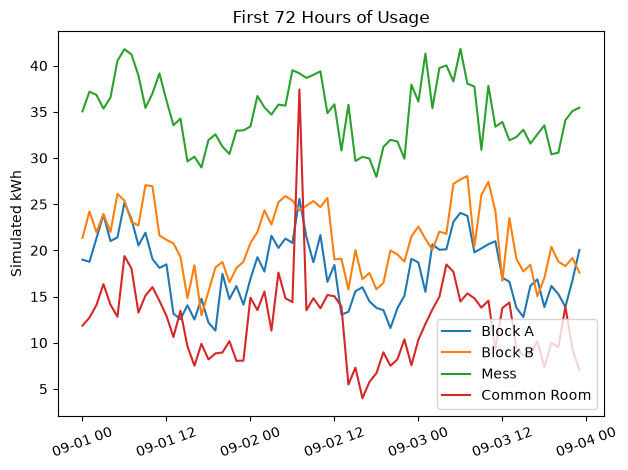

In [15]:
display(df.groupby("area")["kwh"].agg(["mean","min","max"]).round(2))
means = df.groupby("area")["kwh"].mean()
means.plot(kind="bar", figsize=(8,4), title="Average Hourly Electricity Usage by Area", ylabel="Simulated kWh")
plt.tight_layout()
plt.show()
for area in areas:
    part = df[df.area == area].iloc[:72]
    plt.plot(part.timestamp, part.kwh, label=area)
plt.title("First 72 Hours of Usage")
plt.ylabel("Simulated kWh")
plt.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 4. Detect unusual readings

,timestamp,area,kwh,baseline,score
90,2026-09-04 18:00:00,Block A,40.66,17.945,5.851593
117,2026-09-05 21:00:00,Block A,36.19,18.790,4.483304
208,2026-09-09 16:00:00,Block A,37.85,18.795,4.909366
275,2026-09-12 11:00:00,Block A,47.34,18.005,7.555841
286,2026-09-12 22:00:00,Block A,40.10,18.480,5.569698
821,2026-09-05 05:00:00,Block B,44.77,21.990,5.960510
823,2026-09-05 07:00:00,Block B,51.05,21.990,7.603886
876,2026-09-07 12:00:00,Block B,53.10,21.065,8.382396
893,2026-09-08 05:00:00,Block B,46.74,20.825,6.780889
1471,2026-09-02 07:00:00,Common Room,37.42,13.520,6.070417


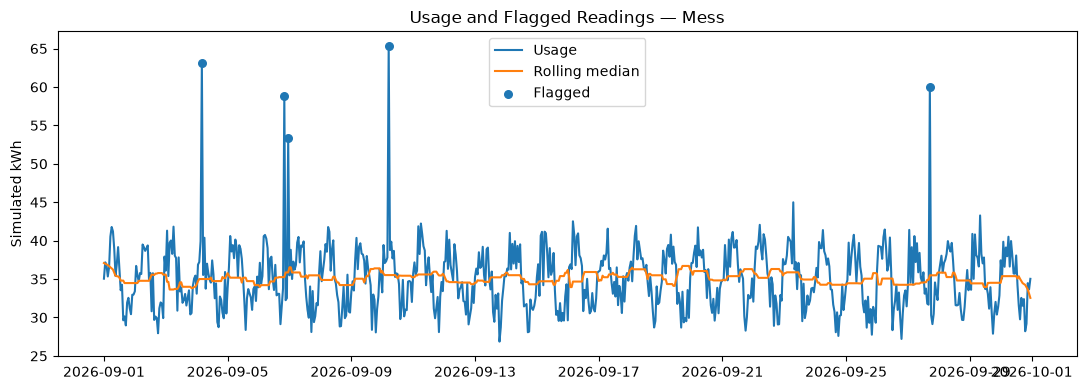

In [16]:
df["baseline"] = df.groupby("area")["kwh"].transform(lambda s: s.rolling(24, min_periods=6, center=True).median())
df["deviation"] = df["kwh"] - df["baseline"]
def robust_score(s):
    center = s.median()
    mad = (s-center).abs().median()
    scale = 1.4826*mad
    return (s-center)/scale if pd.notna(scale) and scale > 1e-9 else pd.Series(0.0, index=s.index)
df["score"] = df.groupby("area")["deviation"].transform(robust_score)
df["anomaly"] = (df["score"] > 4).astype(int)
display(df.loc[df.anomaly == 1, ["timestamp","area","kwh","baseline","score"]].head(15))
part = df[df.area == "Mess"]
plt.figure(figsize=(11,4))
plt.plot(part.timestamp, part.kwh, label="Usage")
plt.plot(part.timestamp, part.baseline, label="Rolling median")
flagged = part[part.anomaly == 1]
plt.scatter(flagged.timestamp, flagged.kwh, label="Flagged", s=30)
plt.title("Usage and Flagged Readings — Mess")
plt.ylabel("Simulated kWh")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Check detection results

In [17]:
tp = int(((df.anomaly==1)&(df.known_anomaly==1)).sum())
fp = int(((df.anomaly==1)&(df.known_anomaly==0)).sum())
fn = int(((df.anomaly==0)&(df.known_anomaly==1)).sum())
precision = tp/(tp+fp) if tp+fp else 0
recall = tp/(tp+fn) if tp+fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print("True positives:",tp," False positives:",fp," Missed spikes:",fn)
print(f"Precision={precision:.3f}, Recall={recall:.3f}, F1={f1:.3f}")

True positives: 19  False positives: 0  Missed spikes: 1
Precision=1.000, Recall=0.950, F1=0.974


## 6. NetworkX area map

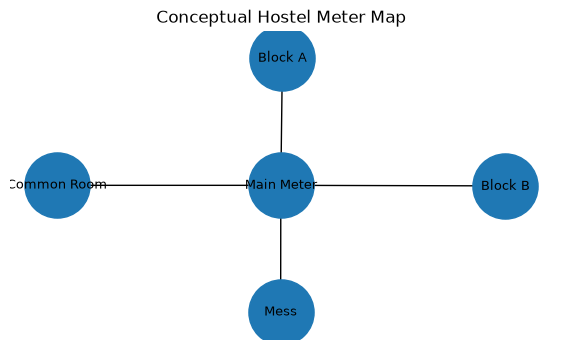

In [18]:
G = nx.Graph()
G.add_edges_from([("Main Meter", a) for a in areas])
plt.figure(figsize=(7,4))
nx.draw_networkx(G, nx.spring_layout(G, seed=7), with_labels=True, node_size=2200, font_size=9)
plt.title("Conceptual Hostel Meter Map")
plt.axis("off")
plt.show()

## 7. SQL database

SQLite runs locally without a server/password. It demonstrates SQL tables, aggregation, and a join. The database is saved in the data folder.

In [19]:
db_path = DATA_DIR/"hostel_electricity.db"
readings = df[["timestamp","area","kwh","known_anomaly"]].copy()
readings["timestamp"] = readings["timestamp"].astype(str)
results = df[["timestamp","area","kwh","score","anomaly"]].copy()
results["timestamp"] = results["timestamp"].astype(str)
with sqlite3.connect(db_path) as conn:
    readings.to_sql("readings", conn, if_exists="replace", index=False)
    results.to_sql("anomaly_results", conn, if_exists="replace", index=False)
    print("SQL summary:")
    display(pd.read_sql_query("SELECT area, ROUND(AVG(kwh),2) AS avg_kwh, MAX(kwh) AS max_kwh, COUNT(*) AS n FROM readings GROUP BY area ORDER BY avg_kwh DESC", conn))
    print("Top flagged readings:")
    display(pd.read_sql_query("SELECT r.timestamp, r.area, r.kwh, a.score FROM readings r JOIN anomaly_results a ON r.timestamp=a.timestamp AND r.area=a.area WHERE a.anomaly=1 ORDER BY a.score DESC LIMIT 10", conn))
print("SQLite database:", db_path)

SQL summary:


,area,avg_kwh,max_kwh,n
0,Mess,35.18,65.32,720
1,Block B,21.17,53.10,720
2,Block A,18.15,47.34,720
3,Common Room,12.21,37.42,720


Top flagged readings:


,timestamp,area,kwh,score
0,2026-09-07 12:00:00,Block B,53.10,8.382396
1,2026-09-05 07:00:00,Block B,51.05,7.603886
2,2026-09-12 11:00:00,Block A,47.34,7.555841
3,2026-09-10 05:00:00,Mess,65.32,7.233792
4,2026-09-04 04:00:00,Mess,63.14,6.829825
5,2026-09-08 05:00:00,Block B,46.74,6.780889
6,2026-09-18 13:00:00,Common Room,37.39,6.477776
7,2026-09-02 07:00:00,Common Room,37.42,6.070417
8,2026-09-05 05:00:00,Block B,44.77,5.960510
9,2026-09-27 17:00:00,Mess,60.02,5.955171


SQLite database: data\hostel_electricity.db


## 8. Optional MySQL Server

This optional section needs MySQL Server running and valid credentials. The SQLite SQL section above works without this setup. Change the settings below only if you know your MySQL login.

In [20]:
USE_MYSQL = False
MYSQL_CONFIG = {"host":"127.0.0.1", "port":3306, "user":"root", "password":"CHANGE_ME"}

if USE_MYSQL:
    try:
        import mysql.connector
        con = mysql.connector.connect(**MYSQL_CONFIG)
        cur = con.cursor()
        cur.execute("CREATE DATABASE IF NOT EXISTS hostel_electricity")
        cur.execute("USE hostel_electricity")
        cur.execute("CREATE TABLE IF NOT EXISTS readings (id INT AUTO_INCREMENT PRIMARY KEY, reading_time DATETIME, area VARCHAR(50), kwh FLOAT, known_anomaly TINYINT)")
        cur.execute("CREATE TABLE IF NOT EXISTS anomaly_results (id INT AUTO_INCREMENT PRIMARY KEY, reading_time DATETIME, area VARCHAR(50), kwh FLOAT, score FLOAT, anomaly TINYINT)")
        cur.execute("DELETE FROM readings")
        cur.execute("DELETE FROM anomaly_results")
        rr = [(pd.Timestamp(r.timestamp).to_pydatetime(), str(r.area), float(r.kwh), int(r.known_anomaly)) for r in df.itertuples(index=False)]
        ar = [(pd.Timestamp(r.timestamp).to_pydatetime(), str(r.area), float(r.kwh), float(r.score), int(r.anomaly)) for r in df[["timestamp","area","kwh","score","anomaly"]].itertuples(index=False, name=None)]
        cur.executemany("INSERT INTO readings (reading_time,area,kwh,known_anomaly) VALUES (%s,%s,%s,%s)", rr)
        cur.executemany("INSERT INTO anomaly_results (reading_time,area,kwh,score,anomaly) VALUES (%s,%s,%s,%s,%s)", ar)
        con.commit()
        cur.execute("SELECT area, ROUND(AVG(kwh),2), COUNT(*) FROM readings GROUP BY area")
        print("MySQL query:", cur.fetchall())
        cur.close(); con.close()
    except Exception as e:
        print("MySQL connection failed:", repr(e))
        print("Check MySQL Server is running and credentials/port are correct.")
else:
    print("MySQL disabled. SQLite SQL database has already been created successfully.")

MySQL disabled. SQLite SQL database has already been created successfully.


## 9. Socket programming

A local TCP server receives one JSON reading from a client on this computer. This is a demonstration, not a connection to physical meters.

In [21]:
def socket_demo():
    state = {"ready":False, "payload":None, "error":None}
    server = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    server.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    server.bind(("127.0.0.1", 0))
    port = server.getsockname()[1]
    def serve():
        try:
            server.listen(1)
            state["ready"] = True
            conn, _ = server.accept()
            with conn:
                data = b""
                while True:
                    chunk = conn.recv(4096)
                    if not chunk: break
                    data += chunk
                state["payload"] = data.decode()
        except Exception as e:
            state["error"] = str(e)
        finally:
            server.close()
    t = threading.Thread(target=serve, daemon=True)
    t.start()
    deadline = time.time()+5
    while not state["ready"] and time.time()<deadline: time.sleep(.01)
    msg = {"timestamp":str(df.iloc[0]["timestamp"]), "area":str(df.iloc[0]["area"]), "kwh":float(df.iloc[0]["kwh"])}
    with socket.create_connection(("127.0.0.1", port), timeout=5) as client:
        client.sendall(json.dumps(msg).encode())
        client.shutdown(socket.SHUT_WR)
    t.join(timeout=5)
    if state["payload"]:
        print("Client sent:", msg)
        print("Server received:", json.loads(state["payload"]))
    else:
        print("Socket demo did not receive data:", state["error"])
socket_demo()

Client sent: {'timestamp': '2026-09-01 00:00:00', 'area': 'Block A', 'kwh': 18.99}
Server received: {'timestamp': '2026-09-01 00:00:00', 'area': 'Block A', 'kwh': 18.99}


## 10. Export results

In [22]:
df.to_csv(DATA_DIR/"hostel_readings_with_flags.csv", index=False)
df.loc[df.anomaly==1].to_csv(DATA_DIR/"flagged_readings.csv", index=False)
print("Saved:")
for name in ["hostel_readings.csv","hostel_readings_with_flags.csv","flagged_readings.csv","hostel_electricity.db"]:
    print(DATA_DIR/name)

Saved:
data\hostel_readings.csv
data\hostel_readings_with_flags.csv
data\flagged_readings.csv
data\hostel_electricity.db


**The readings are simulated. A flag means statistically unusual usage, not proof of theft or equipment failure. The graph is conceptual, and the socket demo uses localhost.**